# Importing libraries

In [23]:
import pandas as pd
import numpy as np

from scipy.optimize import least_squares

import xarray as xr
import rasterio as rio
import geopandas as gpd
from shapely.geometry import mapping
from shapely.geometry import Point
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

import rioxarray
from rasterio.enums import Resampling

import matplotlib.ticker as tck
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

from datetime import datetime

import os
import glob

from PIL import Image

from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject, Resampling

import plotly.graph_objects as go
from plotly.colors import sample_colorscale

from scipy.optimize import minimize_scalar, brentq

import re
import warnings

# Importing Data: P, E, Ep, TWSA, Basin Shapefile

<Axes: >

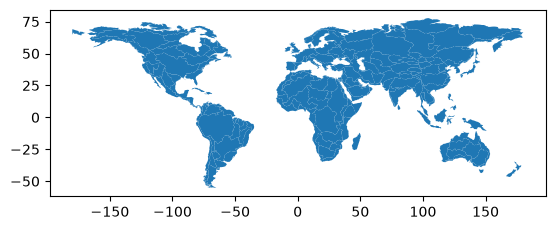

In [2]:
hsd_l3_shp =gpd.read_file(r'D:\Recovered\Recovered\New Volume(E)\Existing Files\college_new_system\Research_study\Helmand Work Team\change_point\Major River Basins Hydrosheds/HydroSHEDS_L3_Filtered_R.shp')
# hsd_l3_shp.head()

# Using a unique identifier for each catchment.
basin_col = "HYBAS_ID"

repr_hsd_l3_shp = hsd_l3_shp.to_crs("EPSG:4326")
# repr_hsd_l3_shp.head()

repr_hsd_l3_shp.plot()

In [3]:
# P = xr.open_dataset(r"E:\objective3_dec\datasets\P\raw_data/P_CRU.nc", decode_times=False)
P = xr.open_dataset(r"D:\new_ballu\CRU_dataset\cru_ts4.07.1901.2022.pre.dat.nc/cru_ts4.07.1901.2022.pre.dat.nc")
P

<xarray.Dataset> Size: 5GB
Dimensions:  (time: 1464, lat: 360, lon: 720)
Coordinates:
  * time     (time) datetime64[ns] 12kB 1901-01-16 1901-02-15 ... 2022-12-16
  * lat      (lat) float32 1kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * lon      (lon) float32 3kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
Data variables:
    pre      (time, lat, lon) float32 2GB ...
    stn      (time, lat, lon) float64 3GB ...
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.07 Precipitation
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2304141047. Data generated from:pre.2304141039.dtb
    history:      Fri 14 Apr 12:49:03 BST 2023 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comment:      Access to these data is available to any registered CEDA user.
    contact:      support@ceda.ac.uk

In [4]:
# Get all yearly NetCDF files
ET = sorted(glob.glob(r"D:\new_ballu\GLEAM_dataset\E\E_*_GLEAM_v4.2a_MO.nc"))

# Open and combine all files along the time dimension
ET = xr.open_mfdataset(ET, combine="by_coords").sortby("time")
ET

<xarray.Dataset> Size: 14GB
Dimensions:  (time: 540, lat: 1800, lon: 3600)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1980-01-31 1980-02-29 ... 2024-12-31
  * lat      (lat) float64 14kB 89.95 89.85 89.75 89.65 ... -89.75 -89.85 -89.95
  * lon      (lon) float64 29kB -179.9 -179.8 -179.8 ... 179.7 179.8 179.9
Data variables:
    E        (time, lat, lon) float32 14GB dask.array<chunksize=(4, 600, 1200), meta=np.ndarray>
Attributes:
    Dataset:      Global Land Evaporation Amsterdam Model
    Version:      4.2a
    Authors:      Hydro-Climate Extremes Lab (H-CEL)
    Institution:  Ghent University
    Contact:      info@gleam.eu
    Reference1:   Miralles, D.G. et al. 2011: Global land-surface evaporation...
    Reference2:   Miralles, D. G., Bonte, O., Koppa, A., Villanueva, O. B., T...

In [5]:
# Get all yearly NetCDF files
PET = sorted(glob.glob(r"D:\new_ballu\GLEAM_dataset\Ep\Ep_*_GLEAM_v4.2a_MO.nc"))

# Open and combine all files along the time dimension
PET = xr.open_mfdataset(PET, combine="by_coords").sortby("time")
PET

<xarray.Dataset> Size: 14GB
Dimensions:  (time: 540, lat: 1800, lon: 3600)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1980-01-31 1980-02-29 ... 2024-12-31
  * lat      (lat) float64 14kB 89.95 89.85 89.75 89.65 ... -89.75 -89.85 -89.95
  * lon      (lon) float64 29kB -179.9 -179.8 -179.8 ... 179.7 179.8 179.9
Data variables:
    Ep       (time, lat, lon) float32 14GB dask.array<chunksize=(4, 600, 1200), meta=np.ndarray>
Attributes:
    Dataset:      Global Land Evaporation Amsterdam Model
    Version:      4.2a
    Authors:      Hydro-Climate Extremes Lab (H-CEL)
    Institution:  Ghent University
    Contact:      info@gleam.eu
    Reference1:   Miralles, D.G. et al. 2011: Global land-surface evaporation...
    Reference2:   Miralles, D. G., Bonte, O., Koppa, A., Villanueva, O. B., T...

In [6]:
rec_twsa = xr.open_dataset(r'E:\objective3_dec\Datasets_ballu\Palazzoli_recon_TWSA_GRAiCE\GRAiCE_BiLSTM.nc')
rec_twsa

<xarray.Dataset> Size: 498MB
Dimensions:  (time: 480, lat: 360, lon: 720)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1984-01-01 1984-02-01 ... 2023-12-01
  * lat      (lat) float32 1kB 89.75 89.25 88.75 88.25 ... -88.75 -89.25 -89.75
  * lon      (lon) float32 3kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
Data variables:
    TWSA     (time, lat, lon) float32 498MB ...
Attributes:
    title:     TWSA reconstruction from 1984 to 2023 - BiLSTM
    subtitle:  Monthly TWSA estimates obtained with BiLSTM model (all predict...
    anything:  Monthly predictors: precipitation, snow depth water equivalent...

# Pre-processing

In [7]:
# Annual precipitation
P_annual = P.resample(time="YS").sum(dim="time")

# Annual evapotranspiration
ET_annual = ET.resample(time="YS").sum(dim="time")

# Annual potential evapotranspiration
PET_annual = PET.resample(time="YS").sum(dim="time")

# Annual TWSC: December-to-December difference in TWSA
twsa = rec_twsa.sortby("time")
dec_twsa = twsa.where(twsa.time.dt.month == 12, drop=True)
TWSC_annual = dec_twsa.diff(dim="time")
# Label each annual change with the ending year
TWSC_annual = TWSC_annual.assign_coords(time=dec_twsa.time.values[1:])

P_annual

<xarray.Dataset> Size: 379MB
Dimensions:  (time: 122, lat: 360, lon: 720)
Coordinates:
  * time     (time) datetime64[ns] 976B 1901-01-01 1902-01-01 ... 2022-01-01
  * lat      (lat) float32 1kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * lon      (lon) float32 3kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
Data variables:
    pre      (time, lat, lon) float32 126MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    stn      (time, lat, lon) float64 253MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.07 Precipitation
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2304141047. Data generated from:pre.2304141039.dtb
    history:      Fri 14 Apr 12:49:03 BST 2023 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comment:      Access to these data is available to any registered CEDA user.
    contact:      support@ceda.ac.uk

In [8]:
annual_datasets = {"P": P_annual, "ET": ET_annual, "PET": PET_annual, "TWSC": TWSC_annual}

In [9]:
# Identifying spatial dimensions and CRS
def prepare_dataset(ds):
    ds = ds.copy()
    x_dim = next((c for c in ["lon", "longitude", "x"] if c in ds.coords), None)
    y_dim = next((c for c in ["lat", "latitude", "y"] if c in ds.coords), None)

    if x_dim is None or y_dim is None:
        raise ValueError(f"Spatial coordinates not identified: {list(ds.coords)}")

    ds = ds.rio.set_spatial_dims(x_dim=x_dim, y_dim=y_dim, inplace=False)

    if ds.rio.crs is None:
        if x_dim in ["lon", "longitude"] and y_dim in ["lat", "latitude"]:
            # Only do this if metadata confirms coordinates are lon/lat in degrees.
            ds = ds.rio.write_crs("EPSG:4326", inplace=False)
        else:
            raise ValueError("CRS is missing. Verify the dataset projection before assigning it.")
    return ds, x_dim, y_dim

# Calculating area-weighted mean for each catchment
catchment_means = {}

for name, ds in annual_datasets.items():
    ds, x_dim, y_dim = prepare_dataset(ds)

    # Reprojecting polygons to the dataset CRS
    basins = hsd_l3_shp.to_crs(ds.rio.crs)

    # cos(latitude) weighting applies to regular geographic grids
    if y_dim not in ["lat", "latitude"] or ds.rio.crs.to_epsg() != 4326:
        raise ValueError(f"{name}: This weighting code requires a regular EPSG:4326 grid.")

    lat_weights = np.cos(np.deg2rad(ds[y_dim])).clip(min=0)
    basin_results = []
    for _, basin in basins.iterrows():

        basin_id = basin[basin_col]

        # Clip to this individual catchment
        clipped = ds.rio.clip([basin.geometry.__geo_interface__], crs=basins.crs, drop=True, all_touched=False)

        # Match latitude weights to the clipped grid
        weights = lat_weights.sel({y_dim: clipped[y_dim]})

        # Area-weighted spatial mean, preserving the annual time dimension
        mean_ds = clipped.weighted(weights).mean(dim=[y_dim, x_dim], skipna=True)
        mean_ds = mean_ds.expand_dims(basin=[basin_id])
        basin_results.append(mean_ds)

    catchment_means[name] = xr.concat(basin_results, dim="basin")

P_catchment = catchment_means["P"]
ET_catchment = catchment_means["ET"]
PET_catchment = catchment_means["PET"]
TWSC_catchment = catchment_means["TWSC"]*10

P_catchment

<xarray.Dataset> Size: 292kB
Dimensions:      (basin: 198, time: 122)
Coordinates:
  * basin        (basin) int64 2kB 1030008100 1030011660 ... 2030071190
  * time         (time) datetime64[ns] 976B 1901-01-01 1902-01-01 ... 2022-01-01
    spatial_ref  int64 8B 0
Data variables:
    pre          (basin, time) float32 97kB 587.5 586.5 579.2 ... 93.33 195.5
    stn          (basin, time) float64 193kB 18.63 18.72 18.24 ... 42.88 34.06
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.07 Precipitation
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2304141047. Data generated from:pre.2304141039.dtb
    history:      Fri 14 Apr 12:49:03 BST 2023 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comment:      Access to these data is available to any registered CEDA user.
    contact:      support@ceda.ac.uk

In [10]:
datasets = {"P": P_catchment, "PET": PET_catchment, "ET": ET_catchment, "TWSC": TWSC_catchment}

In [11]:
start_year = 2003
end_year = 2023

def select_years(da, start_year=2003, end_year=2023):
    # Standardize annual coordinates to integer calendar years
    if "time" in da.dims:
        da = da.assign_coords(time=da["time"].dt.year).rename({"time": "year"})
    elif "year" not in da.dims:
        raise ValueError(f"No 'time' or 'year' dimension found: {da.dims}")
    da = da.sel(year=slice(start_year, end_year))

    # Check that there is at most one observation per year
    years = da["year"].values
    if len(np.unique(years)) != len(years):
        raise ValueError("Multiple observations per year found. " "Check whether the data are truly annual.")
    return da

# Extract the intended variables and standardize their years
P = select_years(P_catchment["pre"], start_year, end_year)
PET = select_years(PET_catchment["Ep"], start_year, end_year)
ET = select_years(ET_catchment["E"], start_year, end_year)
TWSC = select_years(TWSC_catchment["TWSA"], start_year, end_year)

# Align by common year and basin coordinates
P, PET, ET, TWSC = xr.align(P, PET, ET, TWSC, join="inner")

if P.sizes.get("year", 0) == 0:
    raise ValueError("No common years remain after alignment. " "Check the printed year coordinates.")

# Calculate dimensionless indices
valid_P = P.where(np.isfinite(P) & (P > 0))

AI = (PET / valid_P).rename("AI")
EI = (ET / valid_P).rename("EI")
SCI = (TWSC / valid_P).rename("SCI")

AI.attrs["long_name"] = "Aridity Index"
EI.attrs["long_name"] = "Evaporative Index"
SCI.attrs["long_name"] = "Storage Change Index"

indices = xr.Dataset({"AI": AI, "EI": EI, "SCI": SCI})
indices

<xarray.Dataset> Size: 81kB
Dimensions:      (basin: 198, year: 20)
Coordinates:
  * basin        (basin) int64 2kB 1030008100 1030011660 ... 2030071190
  * year         (year) int64 160B 2003 2004 2005 2006 ... 2019 2020 2021 2022
    spatial_ref  int64 8B 0
Data variables:
    AI           (basin, year) float64 32kB dask.array<chunksize=(1, 1), meta=np.ndarray>
    EI           (basin, year) float64 32kB dask.array<chunksize=(1, 1), meta=np.ndarray>
    SCI          (basin, year) float32 16kB -0.001068 -0.004442 ... -0.2172

In [12]:
# print("Number of years:", indices.sizes.get("year", 0))
# print("Number of basins:", indices.sizes.get("basin", 0))

# print("\nIndex ranges:")
# for name in ["AI", "EI", "SCI"]:
#     print(name, "min =", float(indices[name].min(skipna=True).compute()), "max =", float(indices[name].max(skipna=True).compute()))

# print("\nSample observations:")
# print(indices.isel(basin=0).compute())

Number of years: 20
Number of basins: 198

Index ranges:
AI min = 0.28733390345196697 max = 219.01729449584988
EI min = 0.028477956497846544 max = 3.7152522879314405
SCI min = -1.0189279317855835 max = 0.7512203454971313

Sample observations:
<xarray.Dataset> Size: 576B
Dimensions:      (year: 20)
Coordinates:
  * year         (year) int64 160B 2003 2004 2005 2006 ... 2019 2020 2021 2022
    basin        int64 8B 1030008100
    spatial_ref  int64 8B 0
Data variables:
    AI           (year) float64 160B 3.53 3.176 3.667 ... 3.405 3.136 2.803
    EI           (year) float64 160B 0.7579 0.7166 0.6797 ... 0.486 0.4052
    SCI          (year) float32 80B -0.001068 -0.004442 ... -0.0634 0.009423


# 3D Scatter Plot

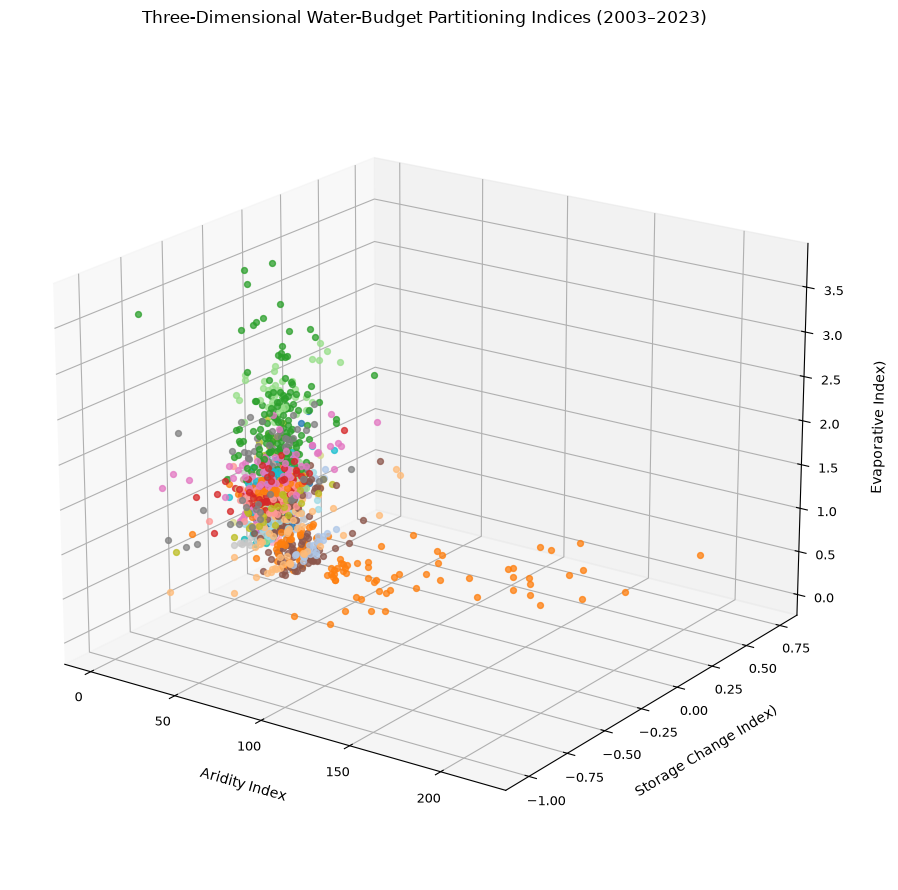

In [13]:
ds_plot = indices.compute()

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

basins = ds_plot["basin"].values
colors = plt.cm.tab20(np.linspace(0, 1, len(basins)))

for i, basin in enumerate(basins):
    ai = ds_plot["AI"].sel(basin=basin).values
    ei = ds_plot["EI"].sel(basin=basin).values
    sci = ds_plot["SCI"].sel(basin=basin).values

    valid = np.isfinite(ai) & np.isfinite(ei) & np.isfinite(sci)

    ax.scatter(ai[valid], sci[valid], ei[valid], color=colors[i], s=18, alpha=0.75, depthshade=False)

# Axis labels
ax.set_xlabel("Aridity Index", labelpad=12)
ax.set_ylabel("Storage Change Index)", labelpad=12)
ax.set_zlabel("Evaporative Index)", labelpad=12)

# Set viewing angle
ax.view_init(elev=20, azim=-55)
ax.tick_params(labelsize=9)
# ax.set_title("Three-Dimensional Water-Budget Partitioning Indices (2003–2023)", pad=20)

plt.tight_layout()
plt.show()

In [14]:
excel_file = r"D:\new_ballu\derivation_generalsed_budyko\obs_data_against_gen_eq_and_others (version 1).xlsx"
sheet_name = 3  # Sheet 4 (pandas uses zero-based indexing)

# Expected Excel columns
basin_id_col = "Basin ID"
basin_name_col = "Basin Name"
aridity_col = "Aridity"

# Plotting limits
ai_min, ai_max = 0, 10
sci_min, sci_max = -1.0, 1.0
ei_min, ei_max = 0, 3

# Aridity-class colors
aridity_colors  = {
    "Humid":     "#2a7f6f",   # teal-green
    "Semi-arid": "#c0812a",   # amber
    "Arid":      "#9b2226",   # deep red
}

# Different marker symbols for individual basins
ALL_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "h", "p", "*"]

# BUDYKO LIMIT FUNCTIONS
def z_upper_np(AI, EI):
    return np.minimum(1 - EI, AI - EI)

def z_lower_np(SCI):
    return np.maximum(-SCI, 0)

df_excel = pd.read_excel(excel_file, sheet_name=sheet_name)

# Remove accidental spaces from column names
df_excel.columns = df_excel.columns.astype(str).str.strip()

# Check the required columns
required_cols = [basin_id_col, basin_name_col, aridity_col]
missing_cols = [c for c in required_cols if c not in df_excel.columns]

if missing_cols:
    raise KeyError(
        f"Missing Excel columns: {missing_cols}. "
        f"Available columns: {df_excel.columns.tolist()}"
    )

# Fill down metadata when subsequent formulation rows have blank cells
df_excel[[basin_id_col, basin_name_col, aridity_col]] = (df_excel[[basin_id_col, basin_name_col, aridity_col]].ffill())

# Keep one row per basin
basins = (df_excel[[basin_id_col, basin_name_col, aridity_col]].drop_duplicates(subset=basin_id_col).dropna(subset=[basin_id_col]).copy())

# Convert basin IDs to numeric values for matching
basins[basin_id_col] = pd.to_numeric(basins[basin_id_col], errors="raise")
basins[aridity_col] = (basins[aridity_col].astype(str).str.strip())

# Normalize common spelling variants if present
aridity_normalization = {"humid": "Humid", "semi-arid": "Semi-arid", "semi arid": "Semi-arid", "arid": "Arid"}
basins[aridity_col] = basins[aridity_col].apply(lambda x: aridity_normalization.get(x.lower(), x))

# Assign markers in the order basins appear in Excel
basin_names = basins[basin_name_col].astype(str).tolist()
basin_markers = {name: ALL_MARKERS[i % len(ALL_MARKERS)] for i, name in enumerate(basin_names)}

# FUNCTION TO SELECT ONE BASIN FROM AN XARRAY ARRAY
def select_basin(da, requested_id):
    basin_dim = next((d for d in ["basin", "HYBAS_ID"] if d in da.dims), None)

    if basin_dim is None:
        raise ValueError(f"No basin dimension found in {da.dims}. " "Expected 'basin' or 'HYBAS_ID'.")

    ids = np.asarray(da[basin_dim].values)

    matches = np.flatnonzero(np.isclose(ids.astype(float), float(requested_id), rtol=0, atol=0))

    if len(matches) == 0:
        raise KeyError(
            f"Basin ID {requested_id} was not found. "
            f"Example available IDs: {ids[:10]}"
        )

    return da.isel({basin_dim: int(matches[0])})

# CALCULATE ANNUAL AI, SCI, AND EI FOR EACH BASIN
all_basin_data = []
basin_errors = []

for _, basin_row in basins.iterrows():

    basin_id = basin_row[basin_id_col]
    basin_name = str(basin_row[basin_name_col])
    aridity = str(basin_row[aridity_col])

    try:
        # Select the basin and load its annual data
        P_b = select_basin(P, basin_id).compute()
        PET_b = select_basin(PET, basin_id).compute()
        ET_b = select_basin(ET, basin_id).compute()
        TWSC_b = select_basin(TWSC, basin_id).compute()

        # Align annual coordinates across all variables
        P_b, PET_b, ET_b, TWSC_b = xr.align(P_b, PET_b, ET_b, TWSC_b, join="inner")

        # Convert the basin data to a DataFrame
        basin_df = pd.DataFrame({
            "P": np.asarray(P_b.values).ravel(),
            "PET": np.asarray(PET_b.values).ravel(),
            "ET": np.asarray(ET_b.values).ravel(),
            "TWSC": np.asarray(TWSC_b.values).ravel(),
        })

        # Retrieve year coordinate
        year_coord = next((c for c in ["year", "time"] if c in P_b.coords), None)

        if year_coord is not None:
            basin_df["year"] = np.asarray(P_b[year_coord].values).ravel()
        else:
            basin_df["year"] = np.arange(len(basin_df))

        # Calculate the three indices
        valid_precipitation = basin_df["P"] > 0

        basin_df["AI"] = (basin_df["PET"] / basin_df["P"].where(valid_precipitation))
        basin_df["EI"] = (basin_df["ET"] / basin_df["P"].where(valid_precipitation))
        basin_df["SCI"] = (basin_df["TWSC"] / basin_df["P"].where(valid_precipitation))

        # Keep finite observations with physically admissible AI
        valid = (np.isfinite(basin_df[["AI", "SCI", "EI"]].to_numpy(dtype=float)).all(axis=1) & valid_precipitation.to_numpy()
            & (basin_df["AI"].to_numpy() >= 0))

        basin_df = basin_df.loc[valid].copy()

        if basin_df.empty:
            print(f"Skipping basin {basin_name} ({basin_id}): no valid data.")
            continue

        # Attach basin metadata to every annual observation
        basin_df["basin_id"] = basin_id
        basin_df["basin_name"] = basin_name
        basin_df["aridity"] = aridity
        basin_df["marker"] = basin_markers[basin_name]

        all_basin_data.append(basin_df)

    except Exception as exc:
        basin_errors.append((basin_id, basin_name, str(exc)))
        print(f"Could not process {basin_name} ({basin_id}): {exc}")


if not all_basin_data:
    raise ValueError("No valid basin observations were generated. " "Check the Excel basin IDs and xarray dimensions.")

plot_df = pd.concat(all_basin_data, ignore_index=True)

print(f"Basins listed in Excel: {len(basins)}")
print(f"Basins successfully plotted: {plot_df['basin_id'].nunique()}")
print(f"Valid basin-year observations: {len(plot_df)}")

if basin_errors:
    print("\nBasins that could not be processed:")
    for basin_id, basin_name, message in basin_errors:
        print(f"  {basin_name} ({basin_id}): {message}")

Basins listed in Excel: 10
Basins successfully plotted: 10
Valid basin-year observations: 200


C:\Users\Satish\AppData\Local\Temp\ipykernel_40684\285110121.py:65: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


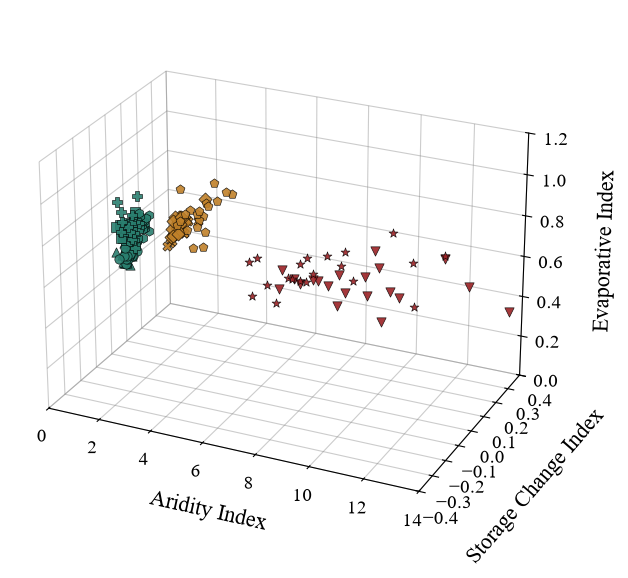

In [15]:
# MATPLOTLIB 3D PLOT: BUDYKO LIMITS + BASIN OBSERVATIONS
ai_min, ai_max = 0, 14
sci_min, sci_max = -1.0, 1.0
ei_min, ei_max = 0, 1.2

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 12

# Initialize 3D figure
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

# Scatter annual observations
for _, basin_row in basins.iterrows():

    basin_name = str(basin_row[basin_name_col])
    aridity_class = str(basin_row[aridity_col])
    basin_id = basin_row[basin_id_col]

    d = plot_df[(plot_df["basin_name"].astype(str) == basin_name) & (plot_df["basin_id"] == basin_id)].copy()

    if d.empty:
        continue

    color = aridity_colors.get(aridity_class, "gray")
    marker = basin_markers[basin_name]

    ax.scatter(d["AI"].to_numpy(), d["SCI"].to_numpy(), d["EI"].to_numpy(), color=color, marker=marker, s=45, alpha=0.90,
        edgecolors="black", linewidths=0.45, depthshade=False)

# Axis labels, limits, and viewing angle
ax.set_xlabel("Aridity Index", fontsize=16, fontfamily="Times New Roman", labelpad=14)
ax.set_ylabel("Storage Change Index", fontsize=16, fontfamily="Times New Roman", labelpad=14)
ax.set_zlabel("Evaporative Index", fontsize=16, fontfamily="Times New Roman", labelpad=14)
plt.setp(ax.get_xticklabels(), fontsize=14, fontfamily="Times New Roman")
plt.setp(ax.get_yticklabels(), fontsize=14, fontfamily="Times New Roman")
plt.setp(ax.get_zticklabels(), fontsize=14, fontfamily="Times New Roman")

ax.set_xlim(ai_min, ai_max)
ax.set_ylim(-0.4, 0.4)
ax.set_zlim(ei_min, ei_max)

ax.set_box_aspect((1.5, 1, 1))
ax.view_init(elev=25, azim=-65)
# ax.set_title("Budyko Limits and Basin-Year Observations", pad=22)

# Make 3D gridlines darker and more visible
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis._axinfo["grid"]["color"] = (0.5, 0.5, 0.5, 0.4)
    axis._axinfo["grid"]["linewidth"] = 0.8
    axis._axinfo["grid"]["linestyle"] = "-"

ax.xaxis.set_pane_color((1, 1, 1, 1))
ax.yaxis.set_pane_color((1, 1, 1, 1))
ax.zaxis.set_pane_color((1, 1, 1, 1))

plt.tight_layout()
# plt.savefig(r"D:\new_ballu\derivation_generalsed_budyko\Figures\new_figures\3d_scatter_10_basins.jpeg", dpi=660, bbox_inches="tight")

plt.show()

# Study Area

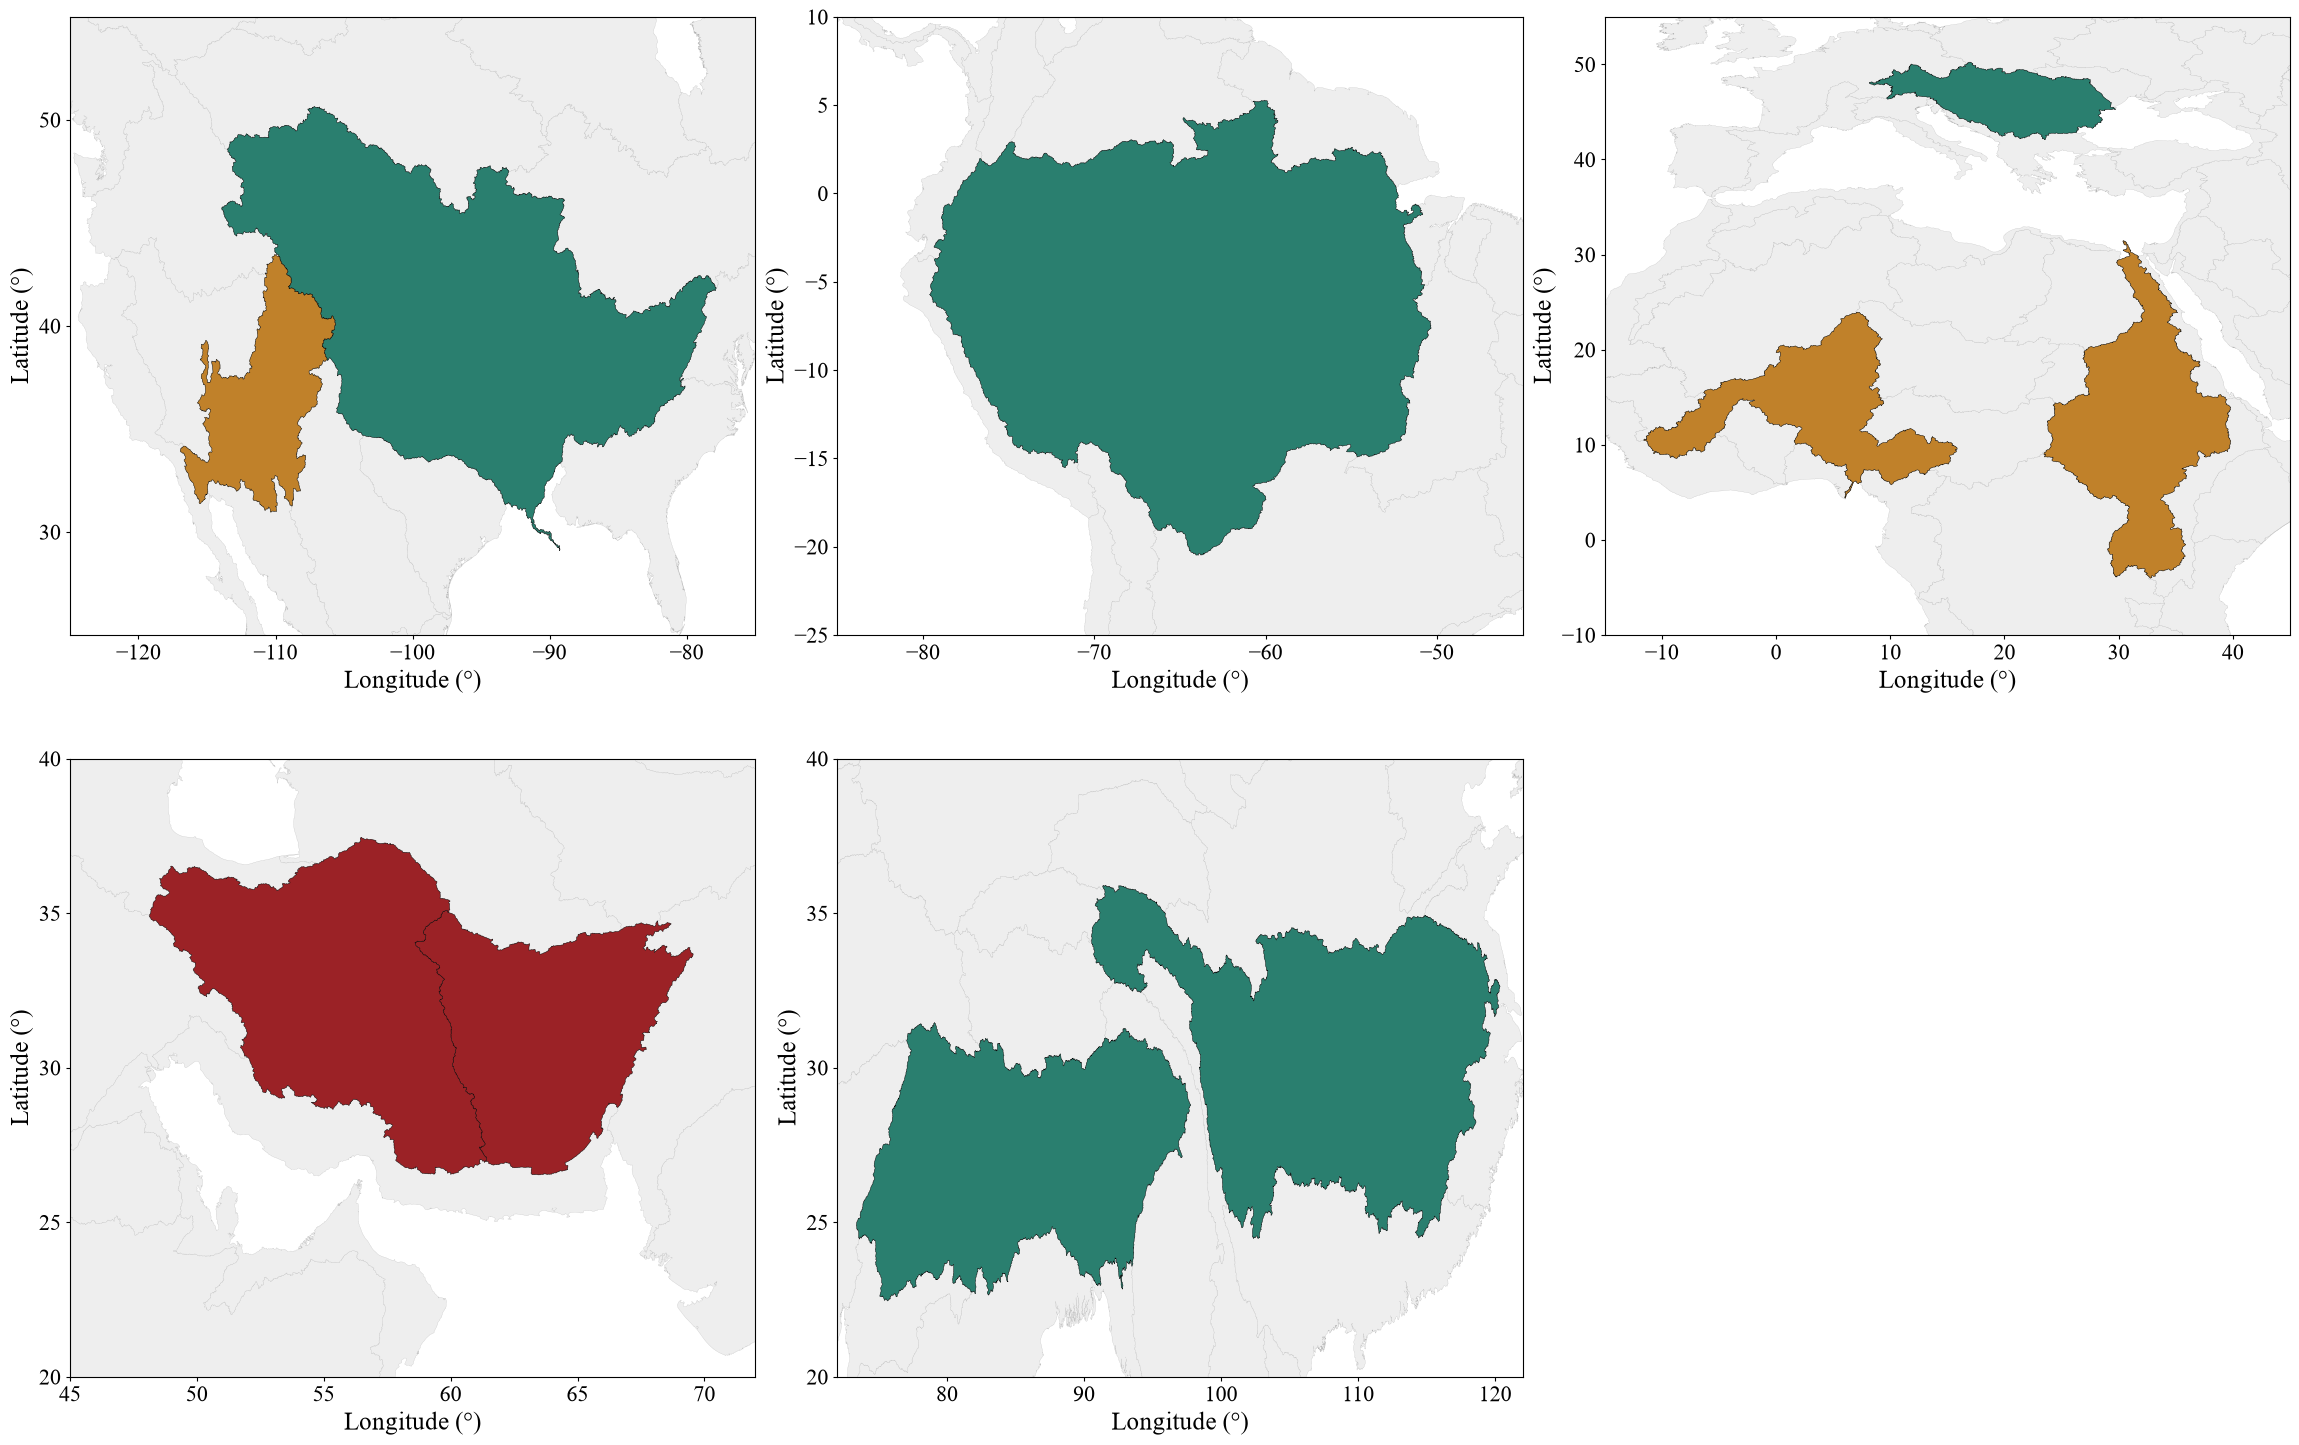

In [16]:
# HydroSHEDS L3 GeoDataFrame already loaded in memory:
gdf = repr_hsd_l3_shp.copy()
basin_id_col_gdf = "HYBAS_ID"

# Same colors as the previous Budyko plots
BACKGROUND_COLOR = "#eeeeee"
BACKGROUND_EDGE = "#b5b5b5"

# # Output files
# output_dir = (r"D:\new_ballu\derivation_generalsed_budyko\figures")

# Assumes the first row contains the actual column headers.
df_excel = pd.read_excel(excel_file, sheet_name=2, header=0)

# Clean column names
df_excel.columns = (df_excel.columns.astype(str).str.strip().str.replace(r"\s+", " ", regex=True))

# print("Excel columns:")
# print(df_excel.columns.tolist())

# Identify required columns
basin_id_col = next((col for col in df_excel.columns
        if "basin" in col.lower() and "id" in col.lower()), None)

aridity_col = next((col for col in df_excel.columns
        if "aridity" in col.lower()), None)

if basin_id_col is None:
    raise ValueError("Basin ID column not found. Check the Excel column names.")

if aridity_col is None:
    raise ValueError("Aridity column not found. Check the Excel column names.")

# print(f"\nBasin ID column: {basin_id_col}")
# print(f"Aridity column: {aridity_col}")

# Convert basin IDs to numeric
df_excel[basin_id_col] = pd.to_numeric(df_excel[basin_id_col], errors="coerce")

# Exclude He et al. (2025), if a Studies column exists
studies_col = next((col for col in df_excel.columns
        if "studies" in col.lower()), None)

if studies_col is not None:
    df_excel = df_excel[~df_excel[studies_col].astype(str).str.contains(r"He\s+et\s+al\.?\s*\(?2025\)?", case=False, regex=True, na=False)].copy()

df_excel = df_excel.dropna(subset=[basin_id_col])

# STANDARDIZE ARIDITY CLASSES
def classify_aridity(value):
    if pd.isna(value):
        return None

    value = str(value).strip().lower()

    if "semi" in value:
        return "semi-arid"
    elif "humid" in value:
        return "humid"
    elif "arid" in value:
        return "arid"

    return None


df_excel["aridity_class"] = df_excel[aridity_col].apply(classify_aridity)

# Keep only basins belonging to the three specified classes
df_excel = df_excel[df_excel["aridity_class"].isin(aridity_colors)].copy()

# If a basin appears more than once, keep its first occurrence
df_excel = df_excel.drop_duplicates(subset=[basin_id_col], keep="first")

# Basin ID -> aridity class
basin_class_map = (df_excel.set_index(basin_id_col)["aridity_class"])

# MATCH EXCEL BASINS TO THE SHAPEFILE
if basin_id_col_gdf not in gdf.columns:
    raise KeyError(f"'{basin_id_col_gdf}' not found in shapefile. "
        f"Available columns: {gdf.columns.tolist()}")

gdf[basin_id_col_gdf] = pd.to_numeric(gdf[basin_id_col_gdf], errors="coerce")
gdf["aridity_class"] = gdf[basin_id_col_gdf].map(basin_class_map)
gdf["selected"] = gdf["aridity_class"].notna()
gdf["plot_color"] = gdf["aridity_class"].map(aridity_colors)

# Use geographic coordinates for latitude and longitude
gdf = gdf.to_crs("EPSG:4326")

# Report matching statistics
excel_ids = set(df_excel[basin_id_col].dropna())
matched_ids = set(gdf.loc[gdf["selected"], basin_id_col_gdf].dropna())

# print("\n========== BASIN MATCHING SUMMARY ==========")
# print(f"Unique Excel basins: {len(excel_ids)}")
# print(f"Matched basin IDs: {len(excel_ids & matched_ids)}")
# print(f"Excel basin IDs not found in shapefile: {len(excel_ids - matched_ids)}")
# print(f"Selected shapefile features: {gdf['selected'].sum()}")

# DEFINE FIVE GEOGRAPHIC EXTENTS
# Format: (longitude_min, longitude_max, latitude_min, latitude_max)
regions = {"(A)": {
        "extent": (-125, -75, 25, 55),
        "lon_interval": 10,
        "lat_interval": 10,
    },
    "(B)": {
        "extent": (-85, -45, -25, 10),
        "lon_interval": 10,
        "lat_interval": 5,
    },
    "(C)": {
        "extent": (-15, 45, -10, 55),
        "lon_interval": 10,
        "lat_interval": 10,
    },
    "(D)": {
        "extent": (45, 72, 20, 40),
        "lon_interval": 5,
        "lat_interval": 5,
    },
    "(E)": {
        "extent": (72, 122, 20, 40),
        "lon_interval": 10,
        "lat_interval": 5,
    },
}

# CREATE A RECTANGULAR 2 x 3 LAYOUT
fig, axes = plt.subplots(2, 3, figsize=(24, 16), gridspec_kw={"left": 0.065, "right": 0.99, "bottom": 0.13, "top": 0.98, "wspace": 0.12,
        "hspace": 0.20})

axes = axes.flatten()

background_gdf = gdf.loc[~gdf["selected"]]
selected_gdf = gdf.loc[gdf["selected"]]

# PLOT THE FIVE REGIONS
for i, (panel_label, region) in enumerate(regions.items()):
    ax = axes[i]
    lon_min, lon_max, lat_min, lat_max = region["extent"]

    # Background basins
    background_gdf.plot(ax=ax, color=BACKGROUND_COLOR, edgecolor=BACKGROUND_EDGE, linewidth=0.15, zorder=1)

    # Selected basins by aridity class
    for aridity, color in aridity_colors.items():

        subset = selected_gdf[selected_gdf["aridity_class"] == aridity]

        if not subset.empty:
            subset.plot(ax=ax, color=color, edgecolor="black", linewidth=0.3, zorder=2)

    # Set geographic extent
    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)

    # Fill each panel consistently
    ax.set_aspect("auto")

    # Latitude and longitude labels
    ax.set_xlabel("Longitude (°)", fontsize=18)
    ax.set_ylabel("Latitude (°)", fontsize=18)

    ax.xaxis.set_major_locator(MultipleLocator(region["lon_interval"]))
    ax.yaxis.set_major_locator(MultipleLocator(region["lat_interval"]))
    ax.tick_params(axis="both", which="major", labelsize=16, direction="out", length=3, width=0.8)

    # No grid lines
    ax.grid(False)

    # Consistent panel borders
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("black")

# REMOVE THE UNUSED SIXTH PANEL
fig.delaxes(axes[5])

# plt.savefig(r"D:\new_ballu\derivation_generalsed_budyko\Figures\new_figures\study_area_10_basins.jpeg", dpi=660, bbox_inches="tight")

plt.show()

# Budyko-type curve(s) and parameter(s): long-term mean & KGE Performance

In [19]:
# We will provide basin id
basin_id = 2030085570  # Replace with your basin HYBAS_ID

# SELECT THE BASIN SAFELY
def select_basin(da, requested_id):
    basin_dim = next((d for d in ["basin", "HYBAS_ID"] if d in da.dims), None)
    if basin_dim is None:
        raise ValueError(f"No basin dimension found in {da.dims}. " "Check the annual DataArray dimensions.")

    ids = np.asarray(da[basin_dim].values)
    matches = np.flatnonzero(np.isclose(ids.astype(float), float(requested_id), rtol=0, atol=0)    )
    if len(matches) == 0:
        raise KeyError(f"Basin {requested_id} not found in this dataset. " f"Example IDs: {ids[:10]}")

    return da.isel({basin_dim: int(matches[0])})

P_b = select_basin(P, basin_id).compute()
PET_b = select_basin(PET, basin_id).compute()
ET_b = select_basin(ET, basin_id).compute()
TWSC_b = select_basin(TWSC, basin_id).compute()

# Match timestamps/years across variables
P_b, PET_b, ET_b, TWSC_b = xr.align(P_b, PET_b, ET_b, TWSC_b, join="inner")

# Extract annual values
df = pd.DataFrame({"P": np.asarray(P_b.values).ravel(), "PET": np.asarray(PET_b.values).ravel(), "ET": np.asarray(ET_b.values).ravel(),
    "TWSC": np.asarray(TWSC_b.values).ravel()})

year_coord = next((c for c in ["year", "time"] if c in P_b.coords), None)
df["year"] = (P_b[year_coord].values if year_coord is not None
    else np.arange(len(df)))

# CALCULATE ANNUAL INDICES
df["AI"] = df["PET"] / df["P"].where(df["P"] > 0)
df["EI"] = df["ET"] / df["P"].where(df["P"] > 0)
df["SCI"] = df["TWSC"] / df["P"].where(df["P"] > 0)

# Effective precipitation: P - TWSC
df["P_eff"] = df["P"] - df["TWSC"]
df["AI_eff"] = df["PET"] / df["P_eff"].where(df["P_eff"] > 0)
df["EI_eff"] = df["ET"] / df["P_eff"].where(df["P_eff"] > 0)

# Use a common set of valid annual observations for the 3D models
m3 = (np.isfinite(df[["AI", "EI", "SCI"]]).all(axis=1) & (df["P"] > 0) & (df["AI"] >= 0))
d3 = df.loc[m3].copy()

if d3.empty:
    raise ValueError(f"No valid annual observations for basin {basin_id}.")

AI = d3["AI"].to_numpy()
EI = d3["EI"].to_numpy()
SCI = d3["SCI"].to_numpy()

AI_mean = np.mean(AI)
EI_mean = np.mean(EI)
SCI_mean = np.mean(SCI)

# MODEL EQUATIONS
def yang_budyko(x, n):
    x = np.maximum(np.asarray(x, dtype=float), 0.0)
    return x / (1.0 + x**n) ** (1.0 / n)

# Our generalized 3D formulation
def generalized_budyko(x, y, n, alpha):
    x, y = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    x = np.maximum(x, 1e-8)

    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        z = np.where(y > 0, x / (1 + x**n)**(1/n) + alpha * y - ((1 - alpha) * (1 + n) * y / (1 + (1/x)**n))**(1/(1+n)),
            (x+y) / (1 + (x+y)**n)**(1/n) - y)
    return z


# Moussa & Lhomme (2016): phi = AI; Hp = -SCI
def moussa_lhomme(x, sci, omega):
    x, sci = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(sci, dtype=float))
    hp = -sci

    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        branch_loss = (1 + x - (1 + (x-hp)**omega)**(1/omega))
        branch_gain = (1 + x + hp - ((1+hp)**omega + x**omega)**(1/omega))

    return np.where(sci <= 0, branch_loss, branch_gain)


# He et al. (2025): DI = AI; WSCI = SCI
def he_2025(x, sci, omega):
    x, sci = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(sci, dtype=float))

    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        branch_loss = (1 + x - (1 + (x+sci)**omega)**(1/omega))
        branch_gain = (1 - sci + x - ((1-sci)**omega + x**omega)**(1/omega))

    return np.where(sci <= 0, branch_loss, branch_gain)

# FIT PARAMETERS AT MEAN INDICES
def fit_yang_mean(ai_values, ei_values):
    """Find n such that Yang curve passes through mean AI and EI."""
    good = (np.isfinite(ai_values) & np.isfinite(ei_values) & (ai_values >= 0))
    xbar = np.mean(ai_values[good])
    ybar = np.mean(ei_values[good])

    def residual(n):
        return yang_budyko(xbar, n) - ybar

    grid = np.geomspace(0.05, 50, 1000)
    vals = np.array([residual(n) for n in grid])

    crossings = np.flatnonzero(vals[:-1] * vals[1:] <= 0)
    if len(crossings):
        i = crossings[0]
        return brentq(residual, grid[i], grid[i+1])

    # If no exact solution exists, find the closest possible curve
    result = minimize_scalar(lambda n: residual(n)**2, bounds=(0.05, 50), method="bounded")
    return result.x

# (a) Traditional Budyko
m_a = (np.isfinite(df["AI"]) & np.isfinite(df["EI"]) & (df["P"] > 0) & (df["AI"] >= 0))
ai_a = df.loc[m_a, "AI"].to_numpy()
ei_a = df.loc[m_a, "EI"].to_numpy()
n_a = fit_yang_mean(ai_a, ei_a)

# (b) Storage-adjusted Budyko
m_b = (np.isfinite(df["AI_eff"]) & np.isfinite(df["EI_eff"]) & (df["P_eff"] > 0) & (df["AI_eff"] >= 0))
ai_b = df.loc[m_b, "AI_eff"].to_numpy()
ei_b = df.loc[m_b, "EI_eff"].to_numpy()
n_b = fit_yang_mean(ai_b, ei_b)

# (c) Our Study
# Specify n and alpha value which can pass mean (we do trial and error)
n_c = 0.5512
alpha_fixed = 0.812

# Simulated annual EI using the specified parameters
EI_sim_c = generalized_budyko(AI, SCI, n_c, alpha_fixed)

# (d) and (e): fit omega at mean AI, SCI, EI
def fit_omega_mean(model):
    def objective(omega):
        pred = model(AI_mean, SCI_mean, omega)
        if not np.all(np.isfinite(pred)):
            return 1e12
        return (float(pred) - EI_mean)**2

    result = minimize_scalar(objective, bounds=(1.01, 20), method="bounded")
    return result.x, result.fun

omega_d, err_d = fit_omega_mean(moussa_lhomme)
omega_e, err_e = fit_omega_mean(he_2025)

print("Fitted parameters")
print(f"(a) Yang n = {n_a:.4f}")
print(f"(b) Adjusted Yang n = {n_b:.4f}")
print(f"(c) Generalized n = {n_c:.4f}, alpha fixed = {alpha_fixed:.3f}")
print(f"(d) Moussa–Lhomme omega = {omega_d:.4f}; error = {err_d:.6g}")
print(f"(e) He et al. omega = {omega_e:.4f}; error = {err_e:.6g}")


Fitted parameters
(a) Yang n = 0.5973
(b) Adjusted Yang n = 0.5816
(c) Generalized n = 0.5512, alpha fixed = 0.812
(d) Moussa–Lhomme omega = 1.3236; error = 9.13327e-15
(e) He et al. omega = 1.3236; error = 9.13327e-15


In [20]:
def calculate_metrics(observed, simulated):
    observed = np.asarray(observed, dtype=float)
    simulated = np.asarray(simulated, dtype=float)

    valid = np.isfinite(observed) & np.isfinite(simulated)
    obs = observed[valid]
    sim = simulated[valid]

    if len(obs) < 2:
        return {"N": len(obs), "KGE": np.nan}

    # KGE (2009 formulation)
    obs_std = np.std(obs, ddof=1)
    sim_std = np.std(sim, ddof=1)
    obs_mean = np.mean(obs)
    sim_mean = np.mean(sim)

    if obs_std > 0 and sim_std > 0 and obs_mean != 0:
        r = np.corrcoef(obs, sim)[0, 1]
        alpha = sim_std / obs_std
        beta = sim_mean / obs_mean
        kge = 1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2)
    else:
        kge = np.nan

    return {"N": len(obs), "KGE": kge}


# Function values evaluated at EACH annual scatter point
predictions = {"(a) Traditional Yang": yang_budyko(df["AI"].to_numpy(), n_a), "(b) Yang with P-TWSC": yang_budyko(df["AI_eff"].to_numpy(), n_b),
               "(c) Generalized Budyko": generalized_budyko(df["AI"].to_numpy(), df["SCI"].to_numpy(), n_c, alpha_fixed),
               "(d) Moussa-Lhomme (2020)": moussa_lhomme(df["AI"].to_numpy(), df["SCI"].to_numpy(), omega_d),
               "(e) He et al. (2025)": he_2025(df["AI"].to_numpy(), df["SCI"].to_numpy(), omega_e)}

# Annual observations for the corresponding panels
observations = {"(a) Traditional Yang": df["EI"].to_numpy(), "(b) Yang with P-TWSC": df["EI_eff"].to_numpy(),
    "(c) Generalized Budyko": df["EI"].to_numpy(), "(d) Moussa-Lhomme (2020)": df["EI"].to_numpy(), "(e) He et al. (2025)": df["EI"].to_numpy()}

results = []
for model_name, simulated in predictions.items():
    metrics = calculate_metrics(observations[model_name], simulated)
    metrics["Model"] = model_name
    results.append(metrics)

metrics_df = pd.DataFrame(results)[["Model", "N", "KGE"]]

print(metrics_df.round(4).to_string(index=False))
# metrics_df.to_csv(f"budyko_metrics_basin_{basin_id}.csv", index=False)

                   Model  N    KGE
    (a) Traditional Yang 20 0.2360
    (b) Yang with P-TWSC 20 0.2690
  (c) Generalized Budyko 20 0.5693
(d) Moussa-Lhomme (2020) 20 0.4706
    (e) He et al. (2025) 20 0.4706


# Box and Whisker Plot & Dot-Strip Plot

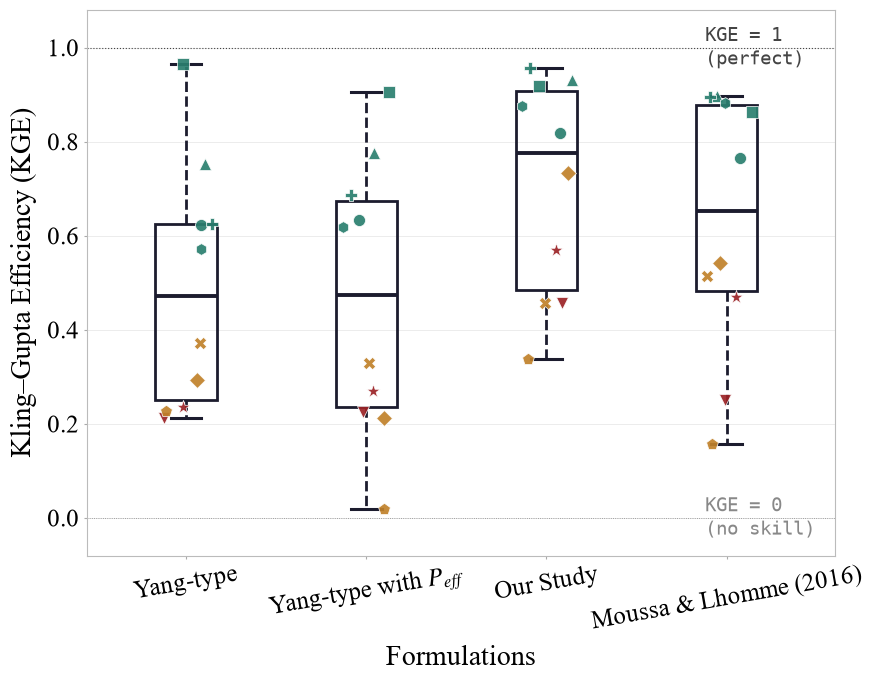

In [36]:
# ─────────────────────────────────────────────────────────────────
# LOAD DATA  —  Sheet 4 of your Excel file
# ─────────────────────────────────────────────────────────────────
excel_path = r"D:\new_ballu\derivation_generalsed_budyko\obs_data_against_gen_eq_and_others (version 1).xlsx"          # ← change to your actual path

df = pd.read_excel(excel_path, sheet_name=3, header=0,) # sheet index 3 = Sheet 4 (0-based)
df.columns   = df.columns.str.strip()
df["Basin Name"] = df["Basin Name"].ffill()
df["Aridity"]    = df["Aridity"].ffill()
df["KGE"]        = pd.to_numeric(df["KGE"], errors="coerce")
df = df.dropna(subset=["Studies", "KGE"])
df["Studies"]    = df["Studies"].str.strip()

# ENCODINGS
aridity_classes = ["Humid", "Semi-arid", "Arid"]

# marker size per symbol (star/pentagon look small at same s)
marker_sizes = {"o": 75, "s": 68, "^": 75, "D": 65, "v": 75, "P": 80, "X": 80, "h": 72, "p": 80, "*": 105}

# formulation order on x-axis
# formulation_order = df["Studies"].unique().tolist()
# ── explicit order if needed: ─────────────────────────────────
formulation_order = ["Yang-type", "Yang-type with $P_{eff}$", "Our Study", "Moussa & Lhomme (2016)"]

fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor("#ffffff")
ax.set_facecolor("#ffffff")

n_forms   = len(formulation_order)
positions = np.arange(1, n_forms + 1)

# ── Box-and-whisker  (no fill, thick lines) ────────────────────
box_data = [df[df["Studies"] == f]["KGE"].dropna().values
    for f in formulation_order]

ax.boxplot(box_data, positions=positions, widths=0.34, patch_artist=True, notch=False, boxprops=dict(linewidth=2.0, color="#1c1c2e", facecolor="none"),
    whiskerprops=dict(linewidth=2.0, color="#1c1c2e", linestyle="--"), capprops=dict(linewidth=2.2, color="#1c1c2e"),
    medianprops =dict(linewidth=2.8, color="#1c1c2e"), flierprops  =dict(marker="", markersize=0),   # hide default fliers
    zorder=3)

# ── Scatter: colour = aridity,  symbol = basin ─────────────────
rng = np.random.default_rng(42)

for f_idx, formulation in enumerate(formulation_order):
    x_pos = positions[f_idx]
    sub   = df[df["Studies"] == formulation]

    for _, row in sub.iterrows():
        basin   = row["Basin Name"]
        aridity = row["Aridity"]
        kge_val = row["KGE"]

        jitter = rng.uniform(-0.15, 0.15)
        mk     = basin_markers[basin]

        ax.scatter(x_pos + jitter, kge_val, color = aridity_colors.get(aridity, "#555555"), marker = mk, s = marker_sizes.get(mk, 72),
            edgecolors = "white", linewidths = 0.55, alpha = 0.92, zorder = 5)

# ── Reference lines ─────────────────────────────────────────────
ax.axhline(1.0, color="#444444", lw=0.8, ls=":", zorder=1)
ax.axhline(0.0, color="#888888", lw=0.6, ls=":", zorder=1)
ax.text(n_forms - 0.12, 1.0, "KGE = 1\n(perfect)", fontsize=14, fontfamily="monospace", color="#444444", va="center", ha="left")
ax.text(n_forms - 0.12, 0.0, "KGE = 0\n(no skill)", fontsize=14, fontfamily="monospace", color="#888888", va="center", ha="left")

# ── Axes ────────────────────────────────────────────────────────
ax.set_xticks(positions)
ax.set_xticklabels(formulation_order, fontsize=18, fontfamily="Times New Roman", rotation=10, ha="center")
# ax.set_xticklabels(formulation_order, fontsize=14, fontfamily="Times New Roman", ha="right")
plt.setp(ax.get_yticklabels(), fontsize=18, fontfamily="Times New Roman")
ax.set_ylabel("Kling–Gupta Efficiency (KGE)", fontsize=20, fontfamily="Times New Roman", labelpad=8)
ax.set_xlabel("Formulations", fontsize=20, fontfamily="Times New Roman", labelpad=8)
ax.set_xlim(0.45, n_forms + 0.6)
ax.set_ylim(min(df["KGE"].min() - 0.10, -0.05), max(df["KGE"].max() + 0.10,  1.08))
# ax.yaxis.set_tick_params(labelsize=14)
ax.tick_params(axis="both", length=2, color="#aaaaaa")
for sp in ax.spines.values():
    sp.set_linewidth(0.8); sp.set_color("#bbbbbb")
ax.yaxis.grid(True, linewidth=0.4, color="#dddddd", zorder=0)
ax.set_axisbelow(True)

# # ── TWO-PART LEGEND ─────────────────────────────────────────────
# # Part 1 — Aridity class (colour, filled circle as key)
# aridity_handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=aridity_colors[a], markeredgecolor="white", markersize=9.5, label=a)
#     for a in aridity_classes]

# # Part 2 — Basin name (marker symbol, dark colour)
# basin_handles = [Line2D([0], [0], marker=basin_markers[b], color="w", markerfacecolor="#555555", markeredgecolor="white", markersize=9.5, label=b)
#     for b in basin_names]

# # separator label
# sep = Line2D([], [], color="none", label=" ")

# leg = ax.legend(handles=([mpatches.Patch(color="none", label="Aridity class")] + aridity_handles + [mpatches.Patch(color="none", label=" "),
#            mpatches.Patch(color="none", label="Basin")] + basin_handles + [mpatches.Patch(facecolor="none", edgecolor="#1c1c2e",
#            linewidth=2.0, label="Box (IQR) + Whiskers")]), fontsize=11, frameon=True, framealpha=0.94, edgecolor="#cccccc", loc="lower left",
#            bbox_to_anchor=(1.01, 0.0),   # outside right edge
#            borderaxespad=0, prop={"family": "Times New Roman", "size": 11})

# # bold the section header entries
# for text in leg.get_texts():
#     if text.get_text() in ("Aridity class", "Basin"):
#         text.set_fontweight("bold")
#         text.set_fontsize(12)

plt.tight_layout()
plt.savefig(r"D:\new_ballu\derivation_generalsed_budyko\Figures\new_figures\kge_boxplot_v2_wo_legend.jpeg", dpi=660, bbox_inches="tight")
plt.show()

# All formulations scatter and fit curve and surface

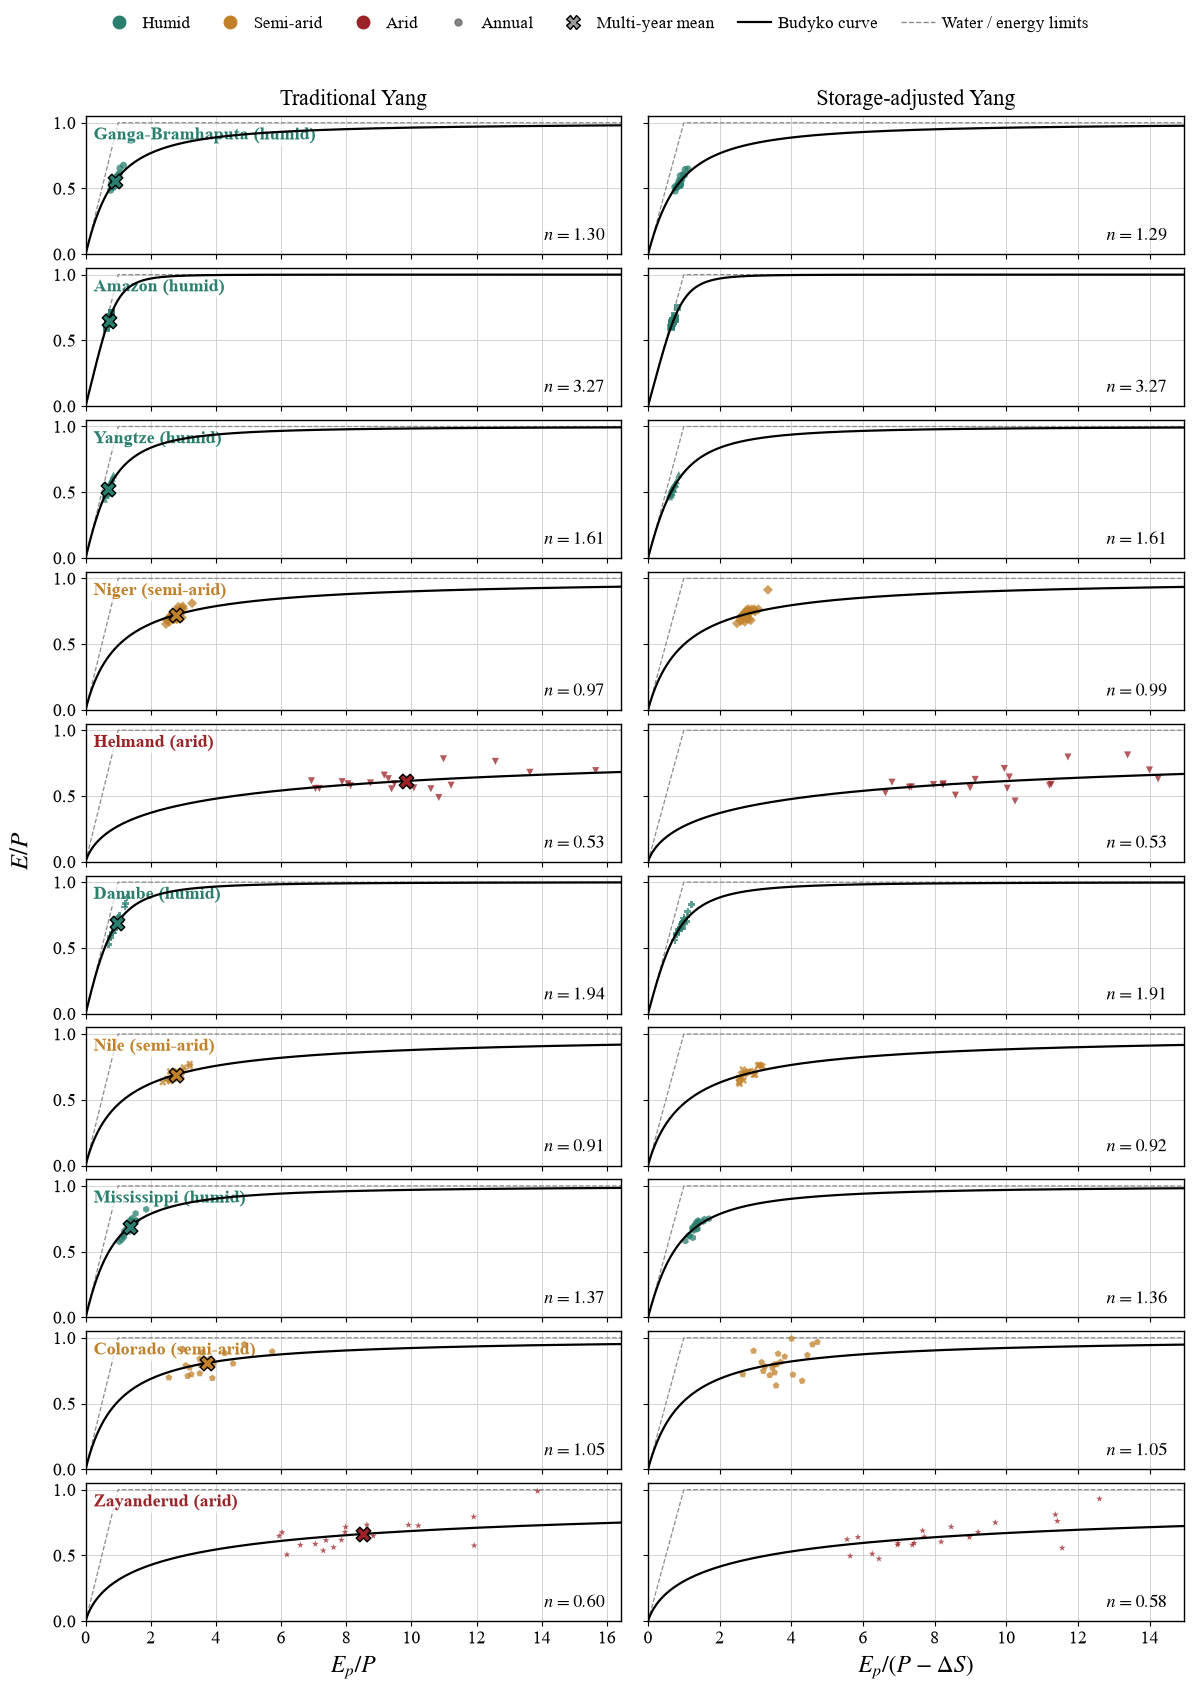

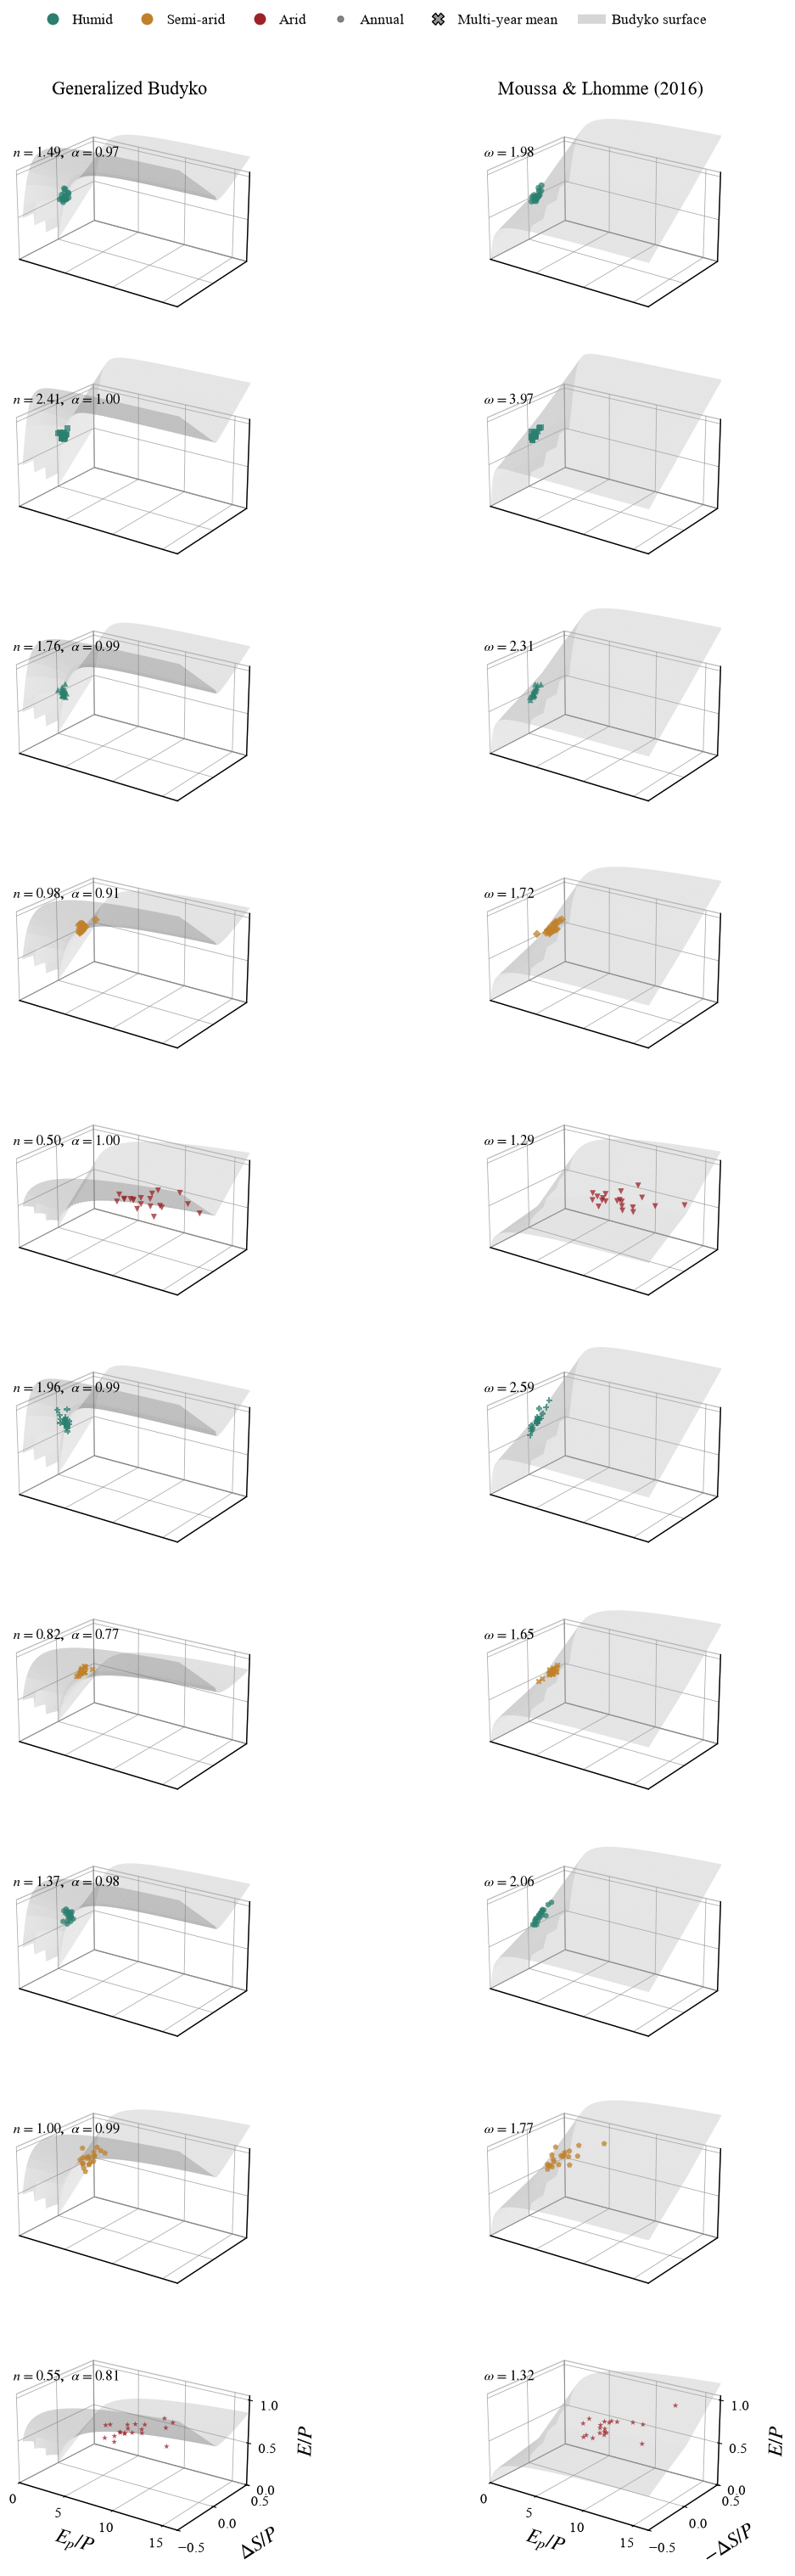

In [24]:
OUTPUT_DIR = r"D:\new_ballu\derivation_generalsed_budyko\Figures\new_figures"
SHEET_NAME = 2          # Sheet 3 (zero-based)
N_BASINS = 10
SAVE_FIGURES = True    # True -> write PNG (600 dpi) and PDF to OUTPUT_DIR

ANNUAL_POINT_SIZE = 26
ANNUAL_POINT_ALPHA = 0.75
MEAN_POINT_SIZE = 110
LIMIT_LINE_COLOR = "0.55"     # water / energy limit lines
SURFACE_COLOR = "#bcbcbc"
SURFACE_ALPHA = 0.30

LABEL_EI = r"$E/P$"
LABEL_AI = r"$E_p/P$"
LABEL_AI_EFF = r"$E_p/(P-\Delta S)$"
LABEL_SCI = r"$\Delta S/P$"
LABEL_MINUS_SCI = r"$-\Delta S/P$"

plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "mathtext.fontset": "stix", "font.size": 13,
    "axes.labelsize": 17, "axes.titlesize": 16, "xtick.labelsize": 13, "ytick.labelsize": 13, "axes.linewidth": 1.0, "savefig.dpi": 600})

os.makedirs(OUTPUT_DIR, exist_ok=True)

def generalized_budyko(x, y, n, alpha):
    x, y = np.broadcast_arrays(np.asarray(x, float), np.asarray(y, float))
    x = np.maximum(x, 1e-8)
    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        pos = (
            x / (1.0 + x**n) ** (1.0 / n)
            + alpha * y
            - (((1.0 - alpha) * (1.0 + n) * y)
               / (1.0 + (1.0 / x) ** n)) ** (1.0 / (1.0 + n))
        )
        non_pos = (x + y) / (1.0 + (x + y) ** n) ** (1.0 / n) - y
        return np.where(y > 0, pos, non_pos)

def moussa_lhomme(x, sci, omega):
    x, sci = np.broadcast_arrays(np.asarray(x, float), np.asarray(sci, float))
    hp = -sci
    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        loss = 1.0 + x - (1.0 + (x - hp) ** omega) ** (1.0 / omega)
        gain = 1.0 + x + hp - ((1.0 + hp) ** omega + x**omega) ** (1.0 / omega)
        return np.where(sci <= 0, loss, gain)

excel = pd.read_excel(excel_file, sheet_name=SHEET_NAME, header=[0, 1])

def clean_header(col):
    parts = [str(v).strip() for v in col
             if not pd.isna(v) and str(v).strip()
             and not str(v).startswith("Unnamed")]
    return " ".join(parts).strip()


excel.columns = [clean_header(c) for c in excel.columns]
excel = excel.dropna(how="all").copy()

BASIN_NAME, BASIN_ID = "Basin Name", "Basin ID"
ARIDITY, STUDY = "Aridity", "Studies"
PARAM_N, PARAM_ALPHA = "Parameter Value n (or omega)", "Parameter Value alpha"
MEAN_AI = "Mean Indices Value AI"
MEAN_EI = "Mean Indices Value EI"
MEAN_SCI = "Mean Indices Value SCI"

required = [BASIN_NAME, BASIN_ID, ARIDITY, STUDY, PARAM_N, PARAM_ALPHA, MEAN_AI, MEAN_EI, MEAN_SCI]
missing = [c for c in required if c not in excel.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}\n"
                     f"Detected columns: {excel.columns.tolist()}")

for col in [BASIN_NAME, BASIN_ID, ARIDITY]:       # merged-cell blanks
    excel[col] = excel[col].ffill()
for col in [BASIN_ID, PARAM_N, PARAM_ALPHA, MEAN_AI, MEAN_EI, MEAN_SCI]:
    excel[col] = pd.to_numeric(excel[col], errors="coerce")

excel = excel.dropna(subset=[BASIN_ID]).copy()
excel[BASIN_ID] = excel[BASIN_ID].astype(np.int64)
excel[STUDY] = excel[STUDY].astype(str).str.strip()

def identify_formulation(name):
    name = str(name).strip().lower()
    if re.search(r"\bhe\b", name) and "2025" in name:       # exclude He et al. (2025)
        return None
    if "moussa" in name and "lhomme" in name:
        return "Moussa-Lhomme"
    if "our study" in name or "generalized" in name:
        return "Generalized"
    if "yang" in name and any(k in name for k in ("eff", "adjust", "storage")):
        return "Storage-adjusted Yang"
    if "yang" in name:
        return "Traditional Yang"
    return None

excel["Formulation"] = excel[STUDY].apply(identify_formulation)
excel = excel[excel["Formulation"].notna()].copy()

dups = excel.duplicated(subset=[BASIN_ID, "Formulation"], keep="first")
if dups.any():
    warnings.warn(f"{int(dups.sum())} duplicate basin/formulation rows; "
                  "using the first of each.")
ROWS = (excel[~dups].set_index([BASIN_ID, "Formulation"]).sort_index())

def normalize_aridity(value):
    value = str(value).strip().lower()
    if "semi" in value:
        return "semi-arid"
    if "humid" in value:
        return "humid"
    if "arid" in value:
        return "arid"
    return None

basin_info = (excel[[BASIN_NAME, BASIN_ID, ARIDITY]].drop_duplicates(subset=[BASIN_ID]).head(N_BASINS).reset_index(drop=True))
if basin_info.empty:
    raise ValueError("No basin IDs found in the sheet.")
if len(basin_info) < N_BASINS:
    warnings.warn(f"Only {len(basin_info)} distinct basins found.")

basin_info["AridityClass"] = basin_info[ARIDITY].apply(normalize_aridity)
basin_info["Color"] = basin_info["AridityClass"].map(aridity_colors).fillna("#777777")
basin_info["Marker"] = [ALL_MARKERS[i % len(ALL_MARKERS)]
                        for i in range(len(basin_info))]
N = len(basin_info)
BASIN_IDS = basin_info[BASIN_ID].tolist()

def get_row(basin_id, formulation):
    try:
        return ROWS.loc[(basin_id, formulation)]
    except KeyError:
        warnings.warn(f"Missing '{formulation}' row for basin ID {basin_id}.")
        return None

def get_value(row, column):
    if row is None or pd.isna(row[column]):
        return np.nan
    return float(row[column])

def get_mean_point(row):
    return (get_value(row, MEAN_AI), get_value(row, MEAN_EI),
            get_value(row, MEAN_SCI))

def select_basin(da, requested_id):
    for dim in ("basin", "HYBAS_ID"):
        if dim not in da.dims:
            continue
        coord = np.asarray(da[dim].values)
        try:
            hits = np.flatnonzero(coord.astype(np.int64) == int(requested_id))
        except (ValueError, TypeError, OverflowError):
            hits = np.flatnonzero(coord == requested_id)
        if len(hits) == 0:
            raise KeyError(f"Basin ID {requested_id} not found in '{dim}'.")
        return da.isel({dim: int(hits[0])}).compute()
    raise KeyError(f"No basin dimension found. Dimensions are {da.dims}.")

def get_basin_data(basin_id):
    p, pet, et, twsc = xr.align(select_basin(P, basin_id), select_basin(PET, basin_id), select_basin(ET, basin_id), select_basin(TWSC, basin_id),
        join="inner")
    df = pd.DataFrame({k: np.asarray(v.values).ravel() for k, v in zip(["P", "PET", "ET", "TWSC"], [p, pet, et, twsc])})

    # traditional indices
    ok = df["P"] > 0
    df["AI"] = np.where(ok, df["PET"] / df["P"], np.nan)
    df["EI"] = np.where(ok, df["ET"] / df["P"], np.nan)
    df["SCI"] = np.where(ok, df["TWSC"] / df["P"], np.nan)

    # storage-adjusted indices
    p_eff = df["P"] - df["TWSC"]
    ok = p_eff > 0
    df["AI_eff"] = np.where(ok, df["PET"] / p_eff, np.nan)
    df["EI_eff"] = np.where(ok, df["ET"] / p_eff, np.nan)

    return df.replace([np.inf, -np.inf], np.nan)

BASIN_DATA = {b: get_basin_data(b) for b in BASIN_IDS}

def finite_max(values):
    v = np.asarray(values, float).ravel()
    v = v[np.isfinite(v)]
    return float(v.max()) if v.size else np.nan

def column_xmax(formulation, annual_col, default):
    vals = []
    for b in BASIN_IDS:
        vals.append(finite_max(BASIN_DATA[b][annual_col]))
        vals.append(get_value(get_row(b, formulation), MEAN_AI))
    vals = [v for v in vals if np.isfinite(v)]
    return max(default, max(vals) * 1.05) if vals else default

YANG_XMAX = column_xmax("Traditional Yang", "AI", 5.0)
ADJ_XMAX = column_xmax("Storage-adjusted Yang", "AI_eff", 5.0)
GEN_XMAX = column_xmax("Generalized", "AI", 3.0)
ML_XMAX = column_xmax("Moussa-Lhomme", "AI", 3.0)

_sci = np.concatenate([BASIN_DATA[b]["SCI"].to_numpy() for b in BASIN_IDS])
_sci = _sci[np.isfinite(_sci)]
SCI_LIM = (max(0.5, np.ceil(np.percentile(np.abs(_sci), 99) * 4) / 4)
           if _sci.size else 0.5)          # symmetric, rounded to 0.25

# SMALL HELPERS
def panel_letter(k):
    return f"({chr(97 + k)})"

def basin_caption(basin):
    cls = basin["AridityClass"] or str(basin[ARIDITY])
    return f"{basin[BASIN_NAME]} ({cls})"

def save_figure(fig, stem, dpi=600, quality=95):
    if SAVE_FIGURES:
        fig.savefig(os.path.join(OUTPUT_DIR, f"{stem}.jpg"), format="jpg", dpi=dpi, bbox_inches="tight", facecolor="white",
                    pil_kwargs={"quality": quality, "optimize": True})


# FIGURE 1  -  2-D Yang panels
def draw_yang_panel(ax, df, xcol, ycol, row, xmax, color, marker):
    # Budyko limits: energy limit (E = Ep) and water limit (E = P)
    ax.plot([0, 1, xmax], [0, 1, 1], ls="--", lw=0.9,
            color=LIMIT_LINE_COLOR, zorder=1)

    ok = np.isfinite(df[xcol]) & np.isfinite(df[ycol])
    ax.scatter(df.loc[ok, xcol], df.loc[ok, ycol], marker=marker,
               s=ANNUAL_POINT_SIZE, color=color, alpha=ANNUAL_POINT_ALPHA,
               edgecolors="none", zorder=3)

    n = get_value(row, PARAM_N)
    if np.isfinite(n):
        xc = np.linspace(0.001, xmax, 1200)
        ax.plot(xc, yang_budyko(xc, n), color="black", lw=1.6, zorder=4)
        ax.text(0.97, 0.07, rf"$n={n:.2f}$", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=13)

    ai_m, ei_m, _ = get_mean_point(row)
    if np.isfinite(ai_m) and np.isfinite(ei_m):
        ax.scatter(ai_m, ei_m, marker="X", s=MEAN_POINT_SIZE, color=color,
                   edgecolor="black", linewidth=1.0, zorder=6)

    ax.set_ylim(0, 1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.grid(True, color="0.8", lw=0.6)
    ax.set_axisbelow(True)

fig1_h = 1.55 * N + 1.5
fig1, axes1 = plt.subplots(N, 2, figsize=(12, fig1_h), sharex="col", sharey=True, squeeze=False)

for i, basin in basin_info.iterrows():
    bid, color, marker = basin[BASIN_ID], basin["Color"], basin["Marker"]
    df = BASIN_DATA[bid]

    draw_yang_panel(axes1[i, 0], df, "AI", "EI", get_row(bid, "Traditional Yang"), YANG_XMAX, color, marker)
    draw_yang_panel(axes1[i, 1], df, "AI_eff", "EI_eff", get_row(bid, "Storage-adjusted Yang"), ADJ_XMAX, color, marker)

    axes1[i, 0].text(0.015, 0.92, f"{basin_caption(basin)}", transform=axes1[i, 0].transAxes, va="top", ha="left",
                     fontsize=13, color=color, fontweight="bold", bbox=dict(fc="white", ec="none", alpha=0.7, pad=1.5), zorder=2.5)

axes1[0, 0].set_xlim(0, YANG_XMAX)
axes1[0, 1].set_xlim(0, ADJ_XMAX)
axes1[0, 0].set_title("Traditional Yang", pad=8)
axes1[0, 1].set_title("Storage-adjusted Yang", pad=8)
axes1[-1, 0].set_xlabel(LABEL_AI, labelpad=6)
axes1[-1, 1].set_xlabel(LABEL_AI_EFF, labelpad=6)
fig1.supylabel(LABEL_EI, x=0.012, fontsize=18)

handles1 = ([Line2D([], [], marker="o", ls="", color=c, markersize=9, label=k.capitalize()) for k, c in aridity_colors.items()]
    + [Line2D([], [], marker="o", ls="", color="0.4", markersize=5, alpha=0.8, label="Annual"),
       Line2D([], [], marker="X", ls="", color="0.6", markeredgecolor="black", markersize=10, label="Multi-year mean"),
       Line2D([], [], color="black", lw=1.6, label="Budyko curve"), Line2D([], [], color=LIMIT_LINE_COLOR, ls="--", lw=1.0,
              label="Water / energy limits")])
fig1.subplots_adjust(left=0.075, right=0.99, top=1 - 1.15 / fig1_h, bottom=0.8 / fig1_h, hspace=0.10, wspace=0.05)
fig1.legend(handles=handles1, loc="upper center", ncol=7, frameon=False,bbox_to_anchor=(0.5, 1.0), fontsize=12, columnspacing=1.4, handletextpad=0.4)

# save_figure(fig1, "Figure_1_Yang_2D")
plt.show()

# FIGURE 2  -  3-D Generalized and Moussa-Lhomme panels
def configure_3d_axes(ax, second_label, xmax, label_axes):
    ax.set_xlim(0, xmax)
    ax.set_ylim(-SCI_LIM, SCI_LIM)
    ax.set_zlim(0, 1.05)
    ax.set_yticks([-SCI_LIM, 0, SCI_LIM])
    ax.set_zticks([0, 0.5, 1.0])
    ax.view_init(elev=22, azim=-55)
    ax.set_box_aspect((1.5, 1, 0.75))
    ax.patch.set_alpha(0)

    if label_axes:
        ax.set_xlabel(LABEL_AI, labelpad=8, fontsize=17)
        ax.set_ylabel(second_label, labelpad=8, fontsize=17)
        ax.set_zlabel(LABEL_EI, labelpad=6, fontsize=17)

    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_facecolor((1, 1, 1, 1))
        axis.pane.set_edgecolor("grey")
        try:
            axis._axinfo["grid"].update(color=(0.5, 0.5, 0.5, 0.65),
                                        linewidth=0.6, linestyle="-")
        except Exception:
            pass
    ax.grid(True)

    if label_axes:
        ax.tick_params(axis="both", which="major", labelsize=12,
                       length=4, width=0.9, pad=1)
        ax.tick_params(axis="z", which="major", labelsize=12,
                       length=4, width=0.9, pad=1)
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ax.set_xticklabels([])
            ax.set_yticklabels([])
            ax.set_zticklabels([])
        ax.tick_params(axis="both", which="both", length=0)
        ax.tick_params(axis="z", which="both", length=0)
        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):     # 3-D tick marks
            try:
                axis._axinfo["tick"].update(inward_factor=0.0,
                                            outward_factor=0.0)
            except Exception:
                pass


def draw_3d_panel(ax, df, row, kind, xmax, color, marker, letter, caption=None):
    # surface first (drawn underneath because computed_zorder=False)
    xg = np.linspace(0.01, xmax, 100)
    yg = np.linspace(-SCI_LIM, SCI_LIM, 75)
    X, Y = np.meshgrid(xg, yg)

    if kind == "generalized":
        n = get_value(row, PARAM_N)
        a = get_value(row, PARAM_ALPHA)
        Z = generalized_budyko(X, Y, n, a) if np.isfinite(n + a) else None
        ycol, y_sign = "SCI", 1.0
        note = rf"$n={n:.2f},\ \alpha={a:.2f}$"
    else:
        w = get_value(row, PARAM_N)
        Z = moussa_lhomme(X, -Y, w) if np.isfinite(w) else None
        ycol, y_sign = "SCI", -1.0
        note = rf"$\omega={w:.2f}$"

    if Z is not None:
        Z = np.where(np.isfinite(Z), Z, np.nan)
        ax.plot_surface(X, Y, Z, color=SURFACE_COLOR, alpha=SURFACE_ALPHA, linewidth=0, antialiased=True, shade=True, zorder=1)

    ok = np.isfinite(df["AI"]) & np.isfinite(df[ycol]) & np.isfinite(df["EI"])
    ax.scatter(df.loc[ok, "AI"], y_sign * df.loc[ok, ycol], df.loc[ok, "EI"], marker=marker, s=ANNUAL_POINT_SIZE, color=color,
               alpha=ANNUAL_POINT_ALPHA, edgecolors="none", depthshade=False, zorder=5)

    ai_m, ei_m, sci_m = get_mean_point(row)
    if np.isfinite(ai_m + ei_m + sci_m):
        ax.scatter(ai_m, y_sign * sci_m, ei_m, marker="X",s=MEAN_POINT_SIZE,color=color,edgecolor="black",linewidth=1.0,depthshade=False,zorder=10)

    head = f"{caption}" if caption else letter
    ax.text2D(0.02, 0.80, note, transform=ax.transAxes, va="top", fontsize=12)


fig2_h = 2.9 * N + 1.5
fig2 = plt.figure(figsize=(12, fig2_h))

for i, basin in basin_info.iterrows():
    bid, color, marker = basin[BASIN_ID], basin["Color"], basin["Marker"]
    df = BASIN_DATA[bid]
    bottom = (i == N - 1)

    ax_g = fig2.add_subplot(N, 2, 2 * i + 1, projection="3d", computed_zorder=False)
    draw_3d_panel(ax_g, df, get_row(bid, "Generalized"), "generalized", GEN_XMAX, color, marker, panel_letter(2 * i), caption=basin_caption(basin))
    configure_3d_axes(ax_g, LABEL_SCI, GEN_XMAX, bottom)

    ax_m = fig2.add_subplot(N, 2, 2 * i + 2, projection="3d", computed_zorder=False)
    draw_3d_panel(ax_m, df, get_row(bid, "Moussa-Lhomme"), "moussa", ML_XMAX, color, marker, panel_letter(2 * i + 1))
    configure_3d_axes(ax_m, LABEL_MINUS_SCI, ML_XMAX, bottom)

    if i == 0:
        ax_g.set_title("Generalized Budyko", pad=2)
        ax_m.set_title("Moussa & Lhomme (2016)", pad=2)

handles2 = handles1[:5] + [Patch(fc=SURFACE_COLOR, ec="none", alpha=0.6, label="Budyko surface")]
fig2.subplots_adjust(left=0.03, right=0.955, top=1 - 1.15 / fig2_h, bottom=0.3 / fig2_h, hspace=0.02, wspace=0.0)
fig2.legend(handles=handles2, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=12, columnspacing=1.4,handletextpad=0.4)

# save_figure(fig2, "Figure_2_Generalized_3D")
plt.show()